# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name: Koen van der Heide**  
**Title of the experiment:**  
**Starting date:**  
**Expected enddate:**  
**Partner:**  
**Goal of the experiment:**  
**Research question:**  
**Expectations or Hypothesis:**  
**Desired accuracy:  $1.380649\cdot10^{−23}\mathrm{J/K}$**  




In [2]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 
from scipy.constants import Boltzmann as K_B

# Preparation
 


**Assignments:**  

**Method:**  
**Theory:**  
**Independent variable:**  
**Dependent variable:**  
**Controlled variablen:**  
**Measurement instruments \& Settings:**  
**Procedure:**  
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  


# Execution

In [3]:
# Measurements: Explain the names of variables provide only raw data in np.arrays!
#Ruwe data + onzekerheden
def vijfhalf(x):
    for i in range(len(U_R2)):
        if U_R2[i]<= 0.2:
            afstelling = 0.2 #Volt
            percentage = 0.004
        if U_R2[i]>= 0.2:                
            afstelling = 2     #Volt
            percentage = 0.003    
    return 0.015*10**-2 *x +percentage*10**-2*afstelling                         #om de spanning over de weerstand te meten is er gewisseld over de afstellingen. 

def driehalf(x):
    afstelling = 40 #Volt
    return 0.7*10**-2 * x+0.01*10**-2*afstelling               #0.7%*aflezing + 0.01%*afstelling
def vijfhalf_weerstand(x):
    afstelling = 2 # K.Ohm
    return 0.02*10**-2*x+0.003*10**-2*afstelling                   #0.02%*x+0.003%*afstelling (voor iedere afstelling)

#Constante
R1=33.149*10**3                          #33 K.Ohm 
R2= 0.99466*10**3                        #1 K.Ohm
R3=100.440                               #100 Ohm

Onzekerheid_R1=vijfhalf_weerstand(R1)
q=-1.6022e-19
n=2
Onzekerheid_n=0.1
Temperatuur_in_celsius=19

Kelvin_bijnulgraden=273.15
T= Kelvin_bijnulgraden+ Temperatuur_in_celsius

Onzekerheid_T=3

Verhouding=R3/(R3+R2)

#Ruwe data
U_R1=np.array([0.011,0.034,0.099,0.204,0.367,0.606,0.765,0.956,1.180,1.453,1.773,2.594,4.457,5.299,6.240,8.630,11.684,20.939,29.430,32.875,58.750,79.943,116.073,149.275,184.470,149.303, 184.510,221.16,259.04,297.78,337.64,377.67,418.34,459.48,501.03,676.76])*10**-3                             #U_R = met 51/2
Onzekerheid_UR2=vijfhalf(U_R1)
U_bron=np.array([0.09,0.19,0.39,0.59,0.79,0.99,1.09,1.19,1.29,1.4,1.49,1.69,1.99,2.09,2.19,2.39,2.59,2.98,3.285,3.39,3.98,4.38,4.98,5.48,5.98,5.48,5.98,6.48,6.98, 7.48,7.98,8.47,8.97,9.47,10.00,12.08     ])*Verhouding                             #3 1/2
Onzekerheid_Ubron=driehalf(U_bron)


# Processing
**Description of processing of raw data into scientific evidence:**


In [8]:
#Bewerkte data

#Voltage over de diode
U_D=U_bron-U_R1
Onzekerheid_UD = np.sqrt(Onzekerheid_Ubron**2+Onzekerheid_UR1**2)
#Stroomsterkte door de diode
I_D=U_R1/R1
Onzekerheid_ID = I_D*np.sqrt(((Onzekerheid_UR1/U_R1)**2)+((Onzekerheid_R1/R1)**2))





#daarna kan je er een logfunctie van maken

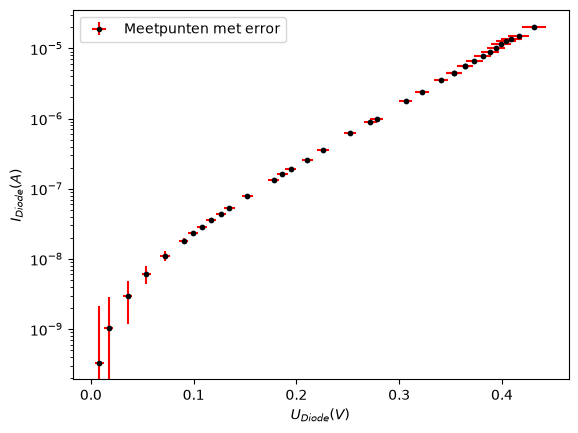

In [9]:
#Plot
#loglog plot maken
xerr= Onzekerheid_UD
yerr= Onzekerheid_ID
plt.figure
plt.plot(U_D,I_D,'.')
plt.errorbar(U_D,I_D,fmt = 'k.',xerr=xerr,yerr=yerr,ecolor = 'r',label = 'Meetpunten met error')
plt.xlabel('$U_{Diode} (V)$')
plt.ylabel('$I_{Diode} (A)$')
plt.yscale('log')          
plt.legend()

**Describing the pattern in the processed data:**  


Constante van boltzmann is 1.42012e-23 +/- 7.33886e-25 J/K
De werkelijke constante is 1.380649e-23 J/K


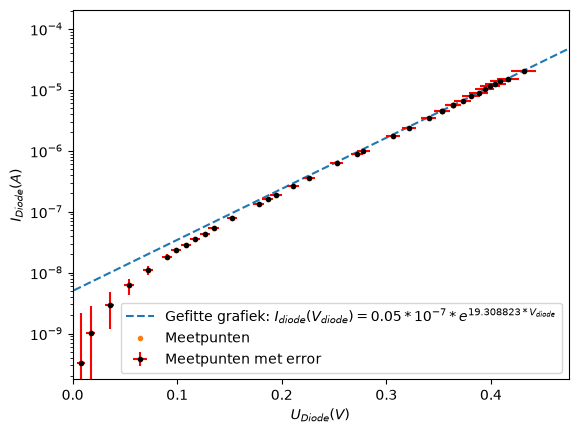

In [10]:
#Calculations of e.a. measurement uncertainties, and providing final answers.
#De fitfunctie: Hierbij is c gelijk aan I0.
def functie(x,b,c):
    return c*np.e**(b*x)


values,covariances=curve_fit(functie, U_D[U_D>0.1],I_D[U_D>0.1]) #U_D moet groter zijn dan 0.1 omdat vanaf 0.1 Volt er een lineaire lijn te bepalen is volgens de fitfunctie 
helling_b=values[0]
afsnede_c=values[1]
Onzekerheid_b=np.sqrt(covariances[0,0])

#testlijn maken
x_test = np.linspace(-1*min(U_D),1.2*max(U_D),1000)
y_test = functie(x_test,values[0],values[1])
plt.plot(x_test,y_test,'--', label='Gefitte grafiek: $ I_{diode}(V_{diode}) = %.2f*10^{-7} * e^{%f * V_{diode}} $' %(values[1]*10**7,values[0]))
plt.xlim(0,1.1*max(U_D))
plt.yscale('log')

plt.xlabel('$U_{Diode} (V)$')
plt.ylabel('$I_{Diode} (A)$')
plt.plot(U_D,I_D,'.', label = 'Meetpunten')
plt.errorbar(U_D,I_D,fmt = 'k.',xerr=xerr,yerr=yerr,ecolor = 'r',label = 'Meetpunten met error')
plt.legend()

#Boltzmann berekenen
k_B =-q/(helling_b*n*T)
Onzekerheid_k_B=k_B*np.sqrt((Onzekerheid_b/helling_b)**2+(Onzekerheid_n/n)**2+(Onzekerheid_T/T)**2)
print('Constante van boltzmann is %.5e +/- %.5e J/K'%(k_B,Onzekerheid_k_B))
print('De werkelijke constante is',K_B,  'J/K')


plt.savefig("punten met een gefitte lijn.png", dpi=400, bbox_inches="tight")

[ 5.52902175e-09  5.96759409e-09  6.96659000e-09  8.00070275e-09
  9.03629487e-09  1.02407706e-08  1.08658638e-08  1.15312423e-08
  1.23875371e-08  1.41656914e-08  1.41148707e-08  1.65650472e-08
  2.11439861e-08  2.28944541e-08  2.59861963e-08  3.11722385e-08
  3.91554445e-08  2.17927301e-08  6.40966077e-08  8.09273903e-08
  7.80840638e-08  8.40649501e-08  9.33382726e-08  8.69499160e-08
  7.46986541e-08  8.36242904e-08  6.91379226e-08  6.01386245e-08
  3.86930484e-08  2.71965434e-08 -6.87439380e-08 -2.69895189e-07
 -3.24604438e-07 -3.92750125e-07  3.20954965e-07  2.22076737e-07]
1.7097349210094657e-08
Jouw waarde is niet strijdig met de constante van Boltzmann.


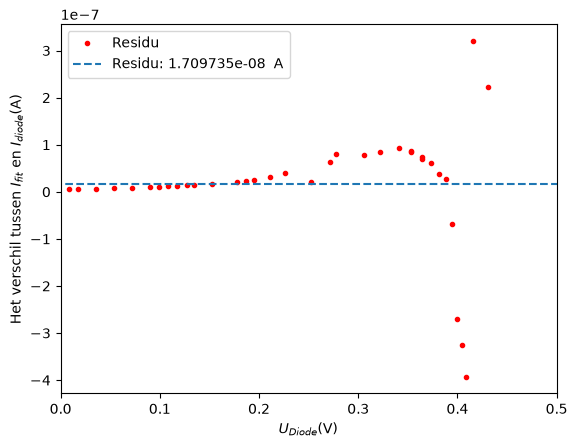

In [11]:
#Residual
Waardes= functie(U_D,values[0],values[1])
Residual =Waardes-I_D
print(Residual)
Residu_gem=np.mean(Residual)
print(Residu_gem)
lijnx=np.array([-1,0.60])
lijny=np.array([Residu_gem,Residu_gem])
plt.plot(U_D,Residual, 'r.', label ='Residu')
plt.xlabel('$U_{Diode}(\\mathrm{V})$')
plt.ylabel('Het verschil tussen $I_{fit}$ en $I_{diode}( \\mathrm{A}$)')
plt.plot(lijnx,lijny,'--',label = 'Residu: %e $\\; \\mathrm{A}$'%(Residu_gem))
plt.xlim(0,0.5)


plt.legend(loc='best')
plt.figure


Onzekerheid_echte_k_B=0
if abs(K_B-k_B)>=2*np.sqrt(Onzekerheid_k_B**2+Onzekerheid_echte_k_B**2):
    print('Jouw waarde is strijdig met de constante van Boltzmann')
else:
    print('Jouw waarde is niet strijdig met de constante van Boltzmann.')


plt.savefig("Residual.png", dpi=400, bbox_inches="tight")

# Discussion



# Conclusion

# Additional notes, remarks, explanations, thoughts etc